In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path
#Load dataset
df = pd.read_csv(str(Path.cwd().parent / "data" / "hepatitis_c.csv"))
data = df
data.head()

,PatientID,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [3]:
# Ubah kolom 'Sex' menjadi tipe kategorikal
data['Sex'] = data['Sex'].astype('category')

In [4]:
# Cek jumlah nilai yang hilang sebelum ditangani
print("Nilai yang hilang sebelum ditangani:")
print(data.isna().sum())

# Untuk kolom kategorikal (seperti 'Sex'), isi dengan modus (nilai yang paling sering muncul)
data['Sex'].fillna(data['Sex'].mode()[0], inplace=True)

# Untuk kolom numerik, imputasi median akan dilakukan di pipeline nanti
# Namun, kita bisa menganalisis pola nilai hilang di sini
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
for col in num_cols:
    if data[col].isna().sum() > 0:
        print(f"\nKolom: {col}")
        print(f"Jumlah nilai hilang: {data[col].isna().sum()}")
        print(f"Median: {data[col].median():.2f}")
        print(f"Rata-rata: {data[col].mean():.2f}")
        print(f"Min: {data[col].min():.2f}, Max: {data[col].max():.2f}")

Nilai yang hilang sebelum ditangani:
PatientID     0
Category      0
Age           0
Sex           0
ALB           1
ALP          18
ALT           1
AST           0
BIL           0
CHE           0
CHOL         10
CREA          0
GGT           0
PROT          1
dtype: int64

Kolom: ALB
Jumlah nilai hilang: 1
Median: 41.95
Rata-rata: 41.62
Min: 14.90, Max: 82.20

Kolom: ALP
Jumlah nilai hilang: 18
Median: 66.20
Rata-rata: 68.28
Min: 11.30, Max: 416.60

Kolom: ALT
Jumlah nilai hilang: 1
Median: 23.00
Rata-rata: 28.45
Min: 0.90, Max: 325.30

Kolom: CHOL
Jumlah nilai hilang: 10
Median: 5.30
Rata-rata: 5.37
Min: 1.43, Max: 9.67

Kolom: PROT
Jumlah nilai hilang: 1
Median: 72.20
Rata-rata: 72.04
Min: 44.80, Max: 90.00


In [5]:
# Cek apakah ada baris yang duplikat
print(f"\nJumlah baris duplikat: {data.duplicated().sum()}")
data.drop_duplicates(inplace=True)


Jumlah baris duplikat: 0


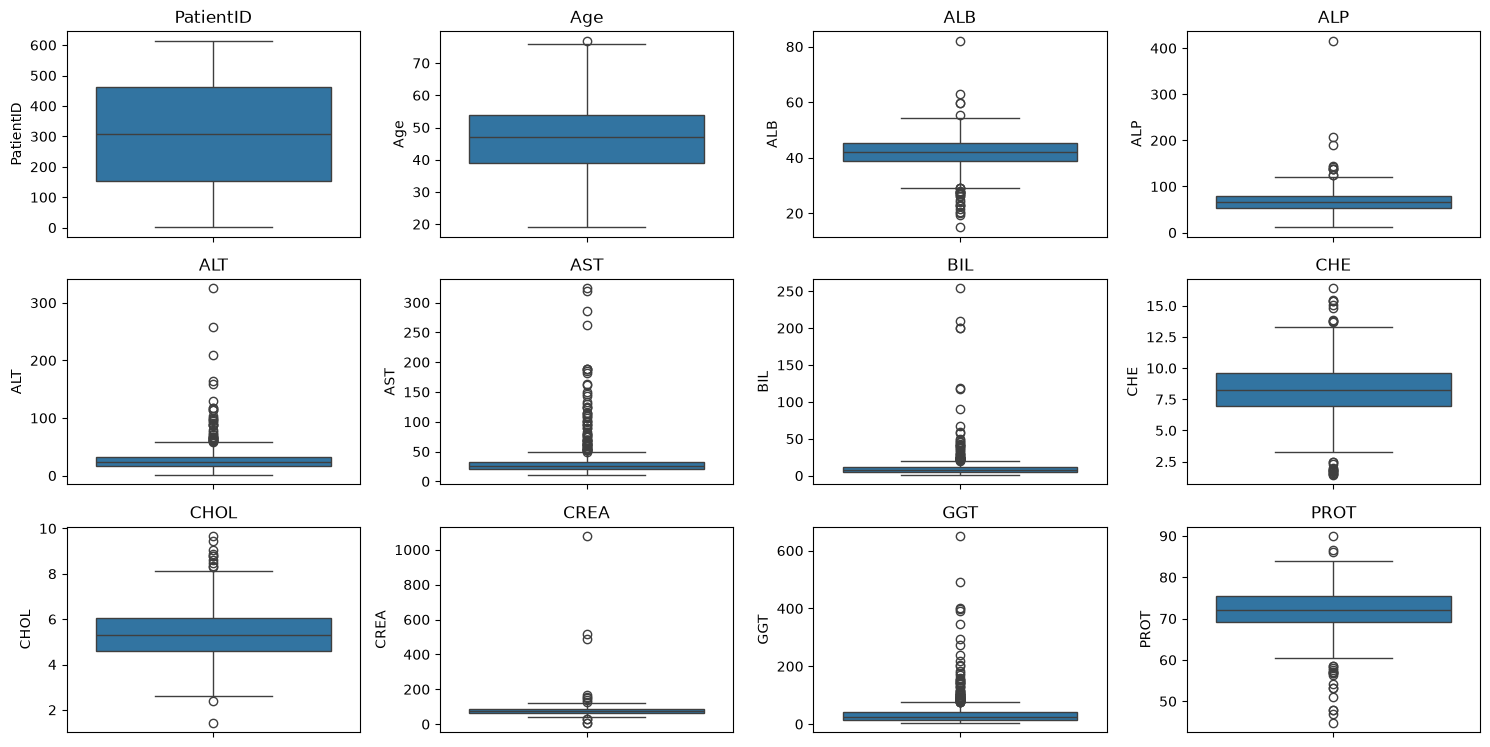

In [6]:
# Visualisasi outlier pada fitur numerik
plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols):
    plt.subplot(4, 4, i+1)
    sns.boxplot(y=data[col])
    plt.title(col)
plt.tight_layout()
plt.show()

# Fungsi untuk menangani outlier menggunakan metode IQR
def handle_outliers(df, columns):
    df_clean = df.copy()
    for col in columns:
        if col in ['Category', 'Sex']:  # Lewati kolom kategorikal
            continue

        # Hitung IQR
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1

        # Tentukan batas bawah dan atas
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Batasi nilai-nilai ekstrem (capping)
        df_clean[col] = np.where(df_clean[col] < lower_bound, lower_bound, df_clean[col])
        df_clean[col] = np.where(df_clean[col] > upper_bound, upper_bound, df_clean[col])

    return df_clean

# Tangani outlier untuk semua kolom numerik
data = handle_outliers(data, num_cols)


In [7]:
# Pisahkan fitur (X) dan target (y)
X = data.drop(['PatientID','Category'], axis=1)
y = data['Category']

In [8]:
# Encode target kategorik
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [9]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

In [10]:
# Preprocessing pipeline
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns
categorical_features = ['Sex']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)])

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.fit_transform(X_test)

In [11]:
# Daftar model klasifikasi
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC(probability=True),
    'XGBoost': xgb.XGBClassifier()
}

# Dictionary untuk menyimpan hasil
results = {}

In [12]:
# Melatih dan mengevaluasi model - model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)
    roc_score = roc_auc_score(y_test, y_pred_proba, multi_class= "ovr")
    print(f"\nModel: {name}")
    print(classification_report(y_test, y_pred))
    print(f"ROC AUC Score: {roc_score}")
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average='weighted'),
        "Recall": recall_score(y_test, y_pred, average='weighted'),
        "F1 Score": f1_score(y_test, y_pred, average='weighted'),
        "ROC AUC Score" : {roc_score}
    }


Model: Logistic Regression
              precision    recall  f1-score   support

           0       0.93      0.99      0.96       153
           1       0.50      0.33      0.40         3
           2       0.83      0.50      0.62        10
           3       0.33      0.25      0.29         8
           4       1.00      0.73      0.84        11

    accuracy                           0.91       185
   macro avg       0.72      0.56      0.62       185
weighted avg       0.90      0.91      0.90       185

ROC AUC Score: 0.9056287809055522

Model: Random Forest
              precision    recall  f1-score   support

           0       0.86      1.00      0.93       153
           1       0.00      0.00      0.00         3
           2       1.00      0.30      0.46        10
           3       0.00      0.00      0.00         8
           4       1.00      0.45      0.62        11

    accuracy                           0.87       185
   macro avg       0.57      0.35      0.40    

<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: Undefine


Model: XGBoost
              precision    recall  f1-score   support

           0       0.92      0.99      0.96       153
           1       0.50      0.33      0.40         3
           2       0.75      0.30      0.43        10
           3       0.38      0.38      0.38         8
           4       1.00      0.55      0.71        11

    accuracy                           0.89       185
   macro avg       0.71      0.51      0.57       185
weighted avg       0.89      0.89      0.88       185

ROC AUC Score: 0.9626593065684119


In [13]:
# Perbandingan model
result_df = pd.DataFrame(results).T
display(result_df.sort_values(by="F1 Score", ascending=False))

,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
Logistic Regression,0.908108,0.898242,0.908108,0.898318,{0.9056287809055522}
XGBoost,0.891892,0.886192,0.891892,0.878457,{0.9626593065684119}
SVM,0.881081,0.867899,0.881081,0.849511,{0.9779061410417395}
Random Forest,0.87027,0.828401,0.87027,0.82899,{0.9635101871230536}


In [14]:
# Voting Classifier (Hard Voting)
voting_hard_clf = VotingClassifier(estimators=[
    ('lr', models["Logistic Regression"]),
    ('rf', models["Random Forest"]),
    ('svc', models["SVM"]),
    ('xgb', models["XGBoost"])
], voting='hard')

voting_hard_clf.fit(X_train, y_train)
y_pred_vote_hard = voting_hard_clf.predict(X_test)
#y_pred_prob_hard = voting_hard_clf.predict_proba(X_test)
#roc_vote_hard = roc_auc_score(y_test, y_pred_prob_hard, multi_class='ovr')

print("\nVoting Classifier (Hard) Performance:")
print(classification_report(y_test, y_pred_vote_hard))
#print(f"ROC AUC Score: {roc_vote_hard}")


Voting Classifier (Hard) Performance:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       153
           1       0.00      0.00      0.00         3
           2       1.00      0.20      0.33        10
           3       0.40      0.25      0.31         8
           4       1.00      0.64      0.78        11

    accuracy                           0.89       185
   macro avg       0.66      0.42      0.47       185
weighted avg       0.87      0.89      0.86       185



<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and bein

In [15]:
# Voting Classifier (Soft Voting)
voting_soft_clf = VotingClassifier(estimators=[
    ('lr', models["Logistic Regression"]),
    ('rf', models["Random Forest"]),
    ('svc', models["SVM"]),
    ('xgb', models["XGBoost"])
], voting='soft')

voting_soft_clf.fit(X_train, y_train)
y_pred_vote_soft = voting_soft_clf.predict(X_test)
y_pred_prob_soft = voting_soft_clf.predict_proba(X_test)
roc_vote_soft = roc_auc_score(y_test, y_pred_prob_soft, multi_class="ovr")

print("\nVoting Classifier (Soft) Performance:")
print(classification_report(y_test, y_pred_vote_soft))
print(f"ROC AUC Score: {roc_vote_soft}")

<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Voting Classifier (Soft) Performance:


              precision    recall  f1-score   support

           0       0.92      0.99      0.96       153
           1       0.00      0.00      0.00         3
           2       1.00      0.50      0.67        10
           3       0.43      0.38      0.40         8
           4       1.00      0.64      0.78        11

    accuracy                           0.90       185
   macro avg       0.67      0.50      0.56       185
weighted avg       0.89      0.90      0.89       185

ROC AUC Score: 0.9704351942692557


In [16]:
# Stacking Classifier
stack_clf = StackingClassifier(
    estimators=[
        ('lr', models["Logistic Regression"]),
        ('rf', models["Random Forest"]),
        ('svc', models["SVM"]),
        ('xgb', models["XGBoost"])
    ],
    final_estimator=LogisticRegression()
)

stack_clf.fit(X_train, y_train)
y_pred_stack = stack_clf.predict(X_test)
y_pred_prob_stack = stack_clf.predict_proba(X_test)
roc_stack = roc_auc_score(y_test, y_pred_prob_stack, multi_class="ovr")

print("\nStacking Classifier Performance:")
print(classification_report(y_test, y_pred_stack))
print(f"ROC AUC Score: {roc_stack}")

<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


<python>\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
<python>\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


<python>\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
<python>\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
<python>\Lib\site-packages\sklearn\svm\_base.


Stacking Classifier Performance:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       153
           1       0.00      0.00      0.00         3
           2       0.75      0.30      0.43        10
           3       0.33      0.38      0.35         8
           4       1.00      0.55      0.71        11

    accuracy                           0.89       185
   macro avg       0.60      0.44      0.49       185
weighted avg       0.88      0.89      0.87       185

ROC AUC Score: 0.9607788177994369


<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [17]:
#Hasil evaluasi
meta_results = {
    'Voting Hard': {
        'Accuracy': accuracy_score(y_test, y_pred_vote_hard),
        'Precision': precision_score(y_test, y_pred_vote_hard, average='weighted'),
        'Recall': recall_score(y_test, y_pred_vote_hard, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred_vote_hard, average='weighted'),
        # ROC AUC tidak tersedia untuk hard voting
        'ROC AUC Score': None
    },
    'Voting Soft': {
        'Accuracy': accuracy_score(y_test, y_pred_vote_soft),
        'Precision': precision_score(y_test, y_pred_vote_soft, average='weighted'),
        'Recall': recall_score(y_test, y_pred_vote_soft, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred_vote_soft, average='weighted'),
        'ROC AUC Score': roc_vote_soft
    },
    'Stacking': {
        'Accuracy': accuracy_score(y_test, y_pred_stack),
        'Precision': precision_score(y_test, y_pred_stack, average='weighted'),
        'Recall': recall_score(y_test, y_pred_stack, average='weighted'),
        'F1 Score': f1_score(y_test, y_pred_stack, average='weighted'),
        'ROC AUC Score': roc_stack
    }
}

<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
<python>\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [18]:
#Simpan hasil menjadi dataframe
meta_df = pd.DataFrame(meta_results).T
#Drop ROC AUC
meta_df_clean = meta_df.dropna(subset=['ROC AUC Score'])

In [19]:
#Hasil evaluasi model meta level
meta_df.head()

,Accuracy,Precision,Recall,F1 Score,ROC AUC Score
Voting Hard,0.886486,0.870782,0.886486,0.858651,NaN
Voting Soft,0.902703,0.893914,0.902703,0.890197,0.970435
Stacking,0.891892,0.876674,0.891892,0.873723,0.960779


<tmp>\ipykernel_1204\762727316.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=meta_df.index, y=meta_df[metric], palette='Set2')
<tmp>\ipykernel_1204\762727316.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=meta_df.index, y=meta_df[metric], palette='Set2')
<tmp>\ipykernel_1204\762727316.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=meta_df.index, y=meta_df[metric], palette='Set2')
<tmp>\ipykernel_1204\762727316.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be remov

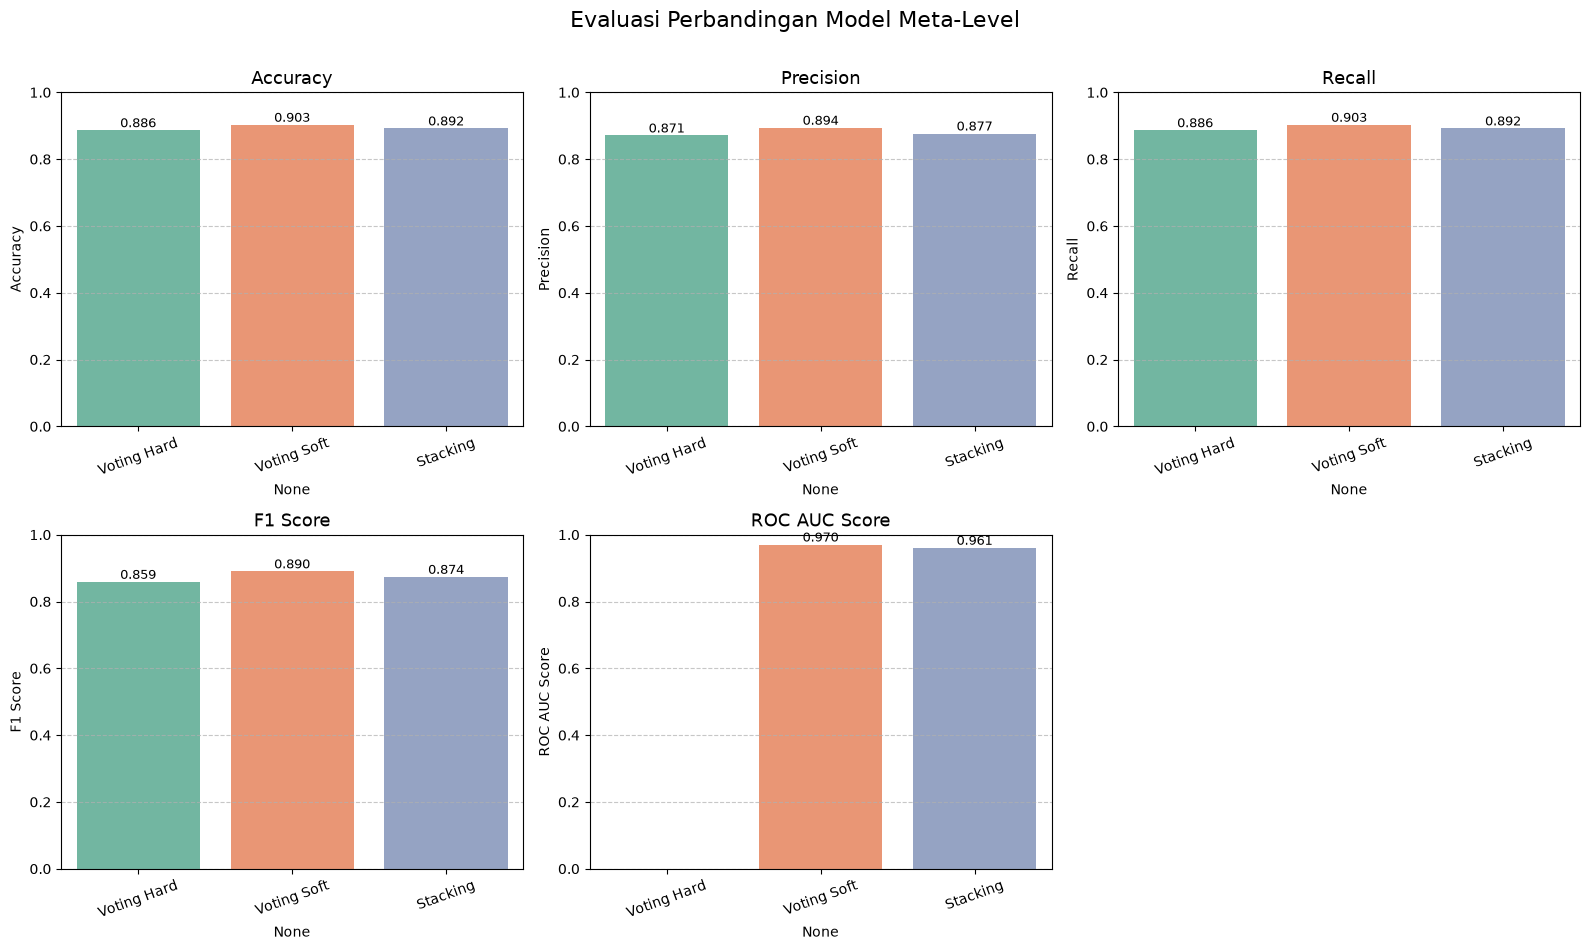

In [20]:
plt.figure(figsize=(16, 9))
for i, metric in enumerate(meta_df.columns, 1):
    plt.subplot(2, 3, i)
    ax = sns.barplot(x=meta_df.index, y=meta_df[metric], palette='Set2')
    plt.title(f'{metric}', fontsize=13)
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    #Tambahkan label angka pada tiap bar
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.3f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, color='black', rotation=0)

plt.tight_layout()
plt.suptitle('Evaluasi Perbandingan Model Meta-Level', fontsize=16, y=1.05)
plt.show()